## **Final Project** <br>
Lauren Hutchinson, Ravindran Hohanavelu, Eric Weldon

In [1]:
#imports
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn import metrics
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from scipy import sparse
%matplotlib inline

In [2]:
#load dataset
spi = pd.read_csv('online_shoppers_intention.csv')
spi.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [7]:
print('Rows:', len(spi))
print('Columns:', len(spi.columns))

Rows: 12330
Columns: 18


In [9]:
#explore features
spi.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [10]:
features = spi.drop('Revenue', axis=1)
target = spi['Revenue']

In [13]:
features.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [15]:
rev = spi['Revenue']
rev.value_counts()

,count
Revenue,
False,10422
True,1908


In [17]:
revenue = spi[spi['Revenue'] == True]
non_revenue = spi[spi['Revenue'] == False]

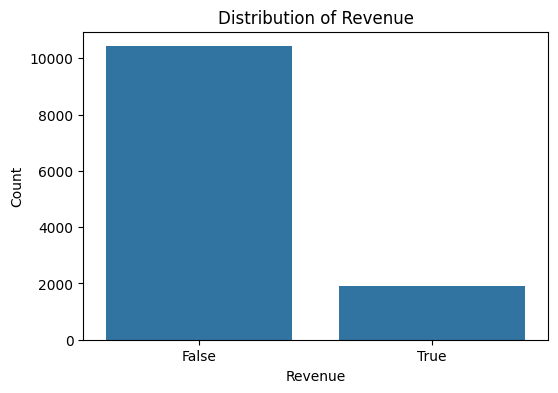

In [27]:
#Exploring the target column. 1 means revenue, and 0 means no revenue.
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.countplot(x='Revenue', data=spi)
plt.title('Distribution of Revenue')
plt.xlabel('Revenue')
plt.ylabel('Count')
plt.show()

In [35]:
nr = spi.groupby('Revenue').size()
nr_percent = nr.to_frame()
nr_percent.reset_index(inplace = True)
nr_percent.rename(columns = {0: 'num_of_customers'}, inplace = True)

In [36]:
total = nr_percent.num_of_customers.sum()
nr_percent['Percentage'] = [nr_percent.num_of_customers[0] / total , nr_percent.num_of_customers[1] / total]
nr_percent

,Revenue,num_of_customers,Percentage
0,False,10422,0.845255
1,True,1908,0.154745


In [41]:
#sample data to balance classes
non_revenue_raw = spi[spi['Revenue'] == 0]
revenue_raw = spi[spi['Revenue'] == 1]
print('Non-Revenue:', len(non_revenue_raw))
print('Revenue:', len(revenue_raw))

Non-Revenue: 10422
Revenue: 1908


In [44]:
percentage = len(revenue_raw)/float(len(non_revenue_raw))
revenue = revenue_raw
non_revenue = non_revenue_raw.sample(frac=percentage, random_state = 42)
revenue_data = pd.concat([revenue, non_revenue])

In [45]:
print("Percentage of revenue sessions:", len(revenue) / float(len(revenue_data)))
print("Percentage of non-revenue session:", len(non_revenue) / float(len(revenue_data)))
print("Total number of sessions:", len(revenue_data))

Percentage of revenue sessions: 0.5
Percentage of non-revenue session: 0.5
Total number of sessions: 3816


In [46]:
revenue_data_rand = revenue_data.sample(frac=1, random_state=42)
revenue_data_rand.Revenue.value_counts()

,count
Revenue,
True,1908
False,1908


In [60]:
#split data into training, validation, and test sets
features2 = ['Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend']
revenue_data2 = revenue_data_rand[features2]
revenue_data2.head()

,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
8284,Nov,2,2,4,10,Returning_Visitor,False
1320,Mar,3,2,7,1,Returning_Visitor,False
1046,Mar,2,2,3,2,Returning_Visitor,False
7824,Sep,2,2,6,3,Returning_Visitor,False
8840,Nov,1,1,2,8,Returning_Visitor,False


In [67]:
X = revenue_data2
y = revenue_data_rand['Revenue']

In [80]:
X = revenue_data_rand.drop('Revenue', axis=1)
y = revenue_data_rand['Revenue']

In [90]:
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size = 0.1, stratify = y, random_state = 0)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, stratify = y_trainval, test_size = 0.2, random_state = 0)

In [91]:
col_cat = ['Month',
       'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType',
       'Weekend']
col_num = ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay']

In [92]:
pipe_cat = make_pipeline(SimpleImputer(strategy = 'constant'), OneHotEncoder(handle_unknown = 'ignore'))
pipe_num = make_pipeline(StandardScaler(), SimpleImputer())

In [93]:
preprocessor = make_column_transformer((pipe_cat, col_cat), (pipe_num, col_num))

In [94]:
pipe = Pipeline([('preprocessing', preprocessor), ('classifier', MLPClassifier(random_state = 42, max_iter = 1500))])

In [95]:
#MLP classifier
param_grid = {'classifier__hidden_layer_sizes': [(10,), (50,), (10, 10), (50, 50)]}
grid = GridSearchCV(pipe, param_grid = param_grid, cv = 5, return_train_score = True)
grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('pipeline-1',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='constant')),
                                                                                         ('onehotencoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Month',
                                                                          'OperatingSystems',
                                                                          'Browser',
                                                                          'Region',
                                                                          'TrafficType',
                                                                          'VisitorType',
                                                                          'Weekend']),
                                                                        ('pipeline-2',
                                                                         Pipeline(steps...
                                                                                          SimpleImputer())]),
                                                                         ['Administrative',
                                                                          'Administrative_Duration',
                                                                          'Informational',
                                                                          'Informational_Duration',
                                                                          'ProductRelated',
                                                                          'ProductRelated_Duration',
                                                                          'BounceRates',
                                                                          'ExitRates',
                                                                          'PageValues',
                                                                          'SpecialDay'])])),
                                       ('classifier',
                                        MLPClassifier(max_iter=1500,
                                                      random_state=42))]),
             param_grid={'classifier__hidden_layer_sizes': [(10,), (50,),
                                                            (10, 10),
                                                            (50, 50)]},
             return_train_score=True)

In [96]:
grid.best_params_

{'classifier__hidden_layer_sizes': (10,)}

In [97]:
#MLP classifier (more hidden layers)

param_grid = {'classifier__hidden_layer_sizes': [(10,), (50,), (100,), (10, 10), (50, 50), (100, 100)]}
grid = GridSearchCV(pipe, param_grid = param_grid, cv = 5, return_train_score = True)
grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(transformers=[('pipeline-1',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='constant')),
                                                                                         ('onehotencoder',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['Month',
                                                                          'OperatingSystems',
                                                                          'Browser',
                                                                          'Region',
                                                                          'TrafficType',
                                                                          'VisitorType',
                                                                          'Weekend']),
                                                                        ('pipeline-2',
                                                                         Pipeline(steps...
                                                                         ['Administrative',
                                                                          'Administrative_Duration',
                                                                          'Informational',
                                                                          'Informational_Duration',
                                                                          'ProductRelated',
                                                                          'ProductRelated_Duration',
                                                                          'BounceRates',
                                                                          'ExitRates',
                                                                          'PageValues',
                                                                          'SpecialDay'])])),
                                       ('classifier',
                                        MLPClassifier(max_iter=1500,
                                                      random_state=42))]),
             param_grid={'classifier__hidden_layer_sizes': [(10,), (50,),
                                                            (100,), (10, 10),
                                                            (50, 50),
                                                            (100, 100)]},
             return_train_score=True)

In [98]:
#same result
grid.best_params_

{'classifier__hidden_layer_sizes': (10,)}

In [99]:
#report score
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, balanced_accuracy_score
X_train_cat = X_train[col_cat]
X_train_num = X_train[col_num]
X_test_cat = X_test[col_cat]
X_test_num = X_test[col_num]

In [100]:
ohe = make_pipeline(SimpleImputer(strategy='constant'), OneHotEncoder())
X_train_cat_enc = ohe.fit_transform(X_train_cat)
X_test_cat_enc = ohe.transform(X_test_cat)

scaler_num = make_pipeline(SimpleImputer(), StandardScaler())
X_train_num_scaled = scaler_num.fit_transform(X_train_num)
X_test_num_scaled = scaler_num.transform(X_test_num)

In [101]:
X_train_scaled = sparse.hstack((X_train_cat_enc, sparse.csr_matrix(X_train_num_scaled)))
X_test_scaled = sparse.hstack((X_test_cat_enc, sparse.csr_matrix(X_test_num_scaled)))

In [102]:
model1 = MLPClassifier(random_state = 0, max_iter = 1500, hidden_layer_sizes = (10,)).fit(X_train_scaled, y_train)

In [103]:
mlp_predicted = model1.predict(X_test_scaled)

In [104]:
print('Accuracy: {:.2f}'.format(accuracy_score(y_test, mlp_predicted)))
print('Precision: {:.2f}'.format(precision_score(y_test, mlp_predicted)))
print('Recall: {:.2f}'.format(recall_score(y_test, mlp_predicted)))
print('F1: {:.2f}'.format(f1_score(y_test, mlp_predicted)))
print('Balanced accuracy: {:.2f}'.format(balanced_accuracy_score(y_test, mlp_predicted)))
print('ROC AUC: {:.2f}'.format(roc_auc_score(y_test, mlp_predicted)))

Accuracy: 0.79
Precision: 0.79
Recall: 0.77
F1: 0.78
Balanced accuracy: 0.79
ROC AUC: 0.79


In [110]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, roc_auc_score, precision_recall_curve,
    roc_curve
)
import matplotlib.pyplot as plt

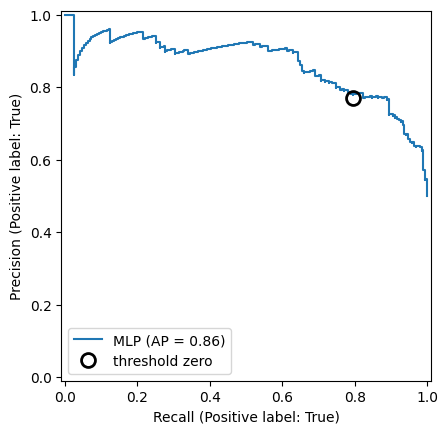

In [119]:
#PRC
from sklearn.metrics import PrecisionRecallDisplay, precision_recall_fscore_support

pr_mlp = PrecisionRecallDisplay.from_estimator(model1, X_test_scaled, y_test, name='MLP')

p_lr, r_lr, _, _ = precision_recall_fscore_support(y_test, model1.predict(X_test_scaled), average='binary')
plt.plot(p_lr, r_lr, 'o', markersize=10, label="threshold zero", fillstyle="none", c='k', mew=2)
plt.legend()

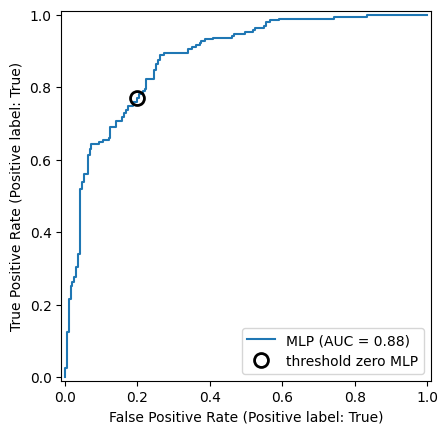

In [125]:
#Model 1 ROC Curve
from sklearn.metrics import RocCurveDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

confusion_mlp = confusion_matrix(y_test, model1.predict(X_test_scaled), normalize='true')

RocCurveDisplay.from_estimator(model1, X_test_scaled, y_test, name='MLP')
plt.plot(confusion_mlp[0, 1], confusion_mlp[1, 1], 'o', markersize=10,
         label="threshold zero MLP", fillstyle="none", c='k', mew=2)
plt.legend(loc=4)
plt.show()

In [126]:
from sklearn.svm import SVC
from sklearn.ensemble import GradientBoostingClassifier

In [127]:
pipe2 = Pipeline([('preprocessing', preprocessor), ('classifier', GradientBoostingClassifier(random_state = 0, n_estimators = 100))])

In [132]:
param_grid2 = {'classifier__max_depth': [6, 8, 10, 12],
              'classifier__n_estimators': [250, 275, 300, 325, 350]}

In [133]:
grid2 = GridSearchCV(pipe2, param_grid = param_grid2, cv = 5, return_train_score = True)
grid2.fit(X_train, y_train)

accuracy = grid2.score(X_trainval, y_trainval)
print('Accuracy score of the {} is {:.3f}'.format(grid2.__class__.__name__, accuracy))

Accuracy score of the GridSearchCV is 0.969


In [134]:
grid2.best_params_

{'classifier__max_depth': 12, 'classifier__n_estimators': 350}

In [136]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, balanced_accuracy_score
model2 = GradientBoostingClassifier(random_state = 0, n_estimators = 350, max_depth = 12).fit(X_train_scaled, y_train)

In [139]:
gbc_predicted = model2.predict(X_test_scaled)

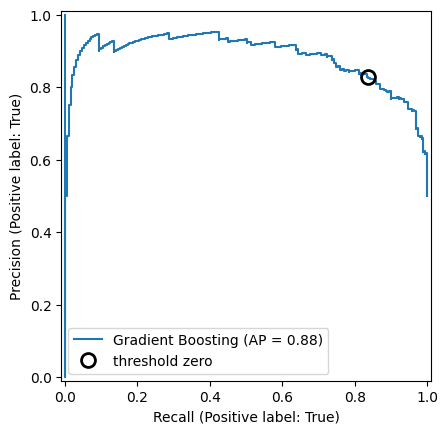

In [141]:
#Model 2 PRC
from sklearn.metrics import PrecisionRecallDisplay, precision_recall_fscore_support

pr_mlp = PrecisionRecallDisplay.from_estimator(model2, X_test_scaled, y_test, name='Gradient Boosting')

p_lr, r_lr, _, _ = precision_recall_fscore_support(y_test, model2.predict(X_test_scaled), average='binary')
plt.plot(p_lr, r_lr, 'o', markersize=10, label="threshold zero", fillstyle="none", c='k', mew=2)
plt.legend()

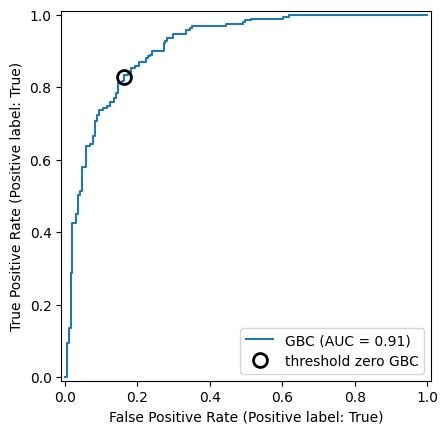

In [143]:
#Model 2 ROC
from sklearn.metrics import RocCurveDisplay, confusion_matrix

confusion_gbc = confusion_matrix(y_test, model2.predict(X_test_scaled), normalize='true')

RocCurveDisplay.from_estimator(model2, X_test_scaled, y_test, name='GBC')
plt.plot(confusion_gbc[0, 1], confusion_gbc[1, 1], 'o', markersize=10,
         label="threshold zero GBC", fillstyle="none", c='k', mew=2)
plt.legend(loc=4)
plt.show()

In [144]:
print('Accuracy: {:.2f}'.format(accuracy_score(y_test, gbc_predicted)))
print('Precision: {:.2f}'.format(precision_score(y_test, gbc_predicted)))
print('Recall: {:.2f}'.format(recall_score(y_test, gbc_predicted)))
print('F1: {:.2f}'.format(f1_score(y_test, gbc_predicted)))
print('Balanced accuracy: {:.2f}'.format(balanced_accuracy_score(y_test, gbc_predicted)))
print('ROC AUC: {:.2f}'.format(roc_auc_score(y_test, gbc_predicted)))

Accuracy: 0.83
Precision: 0.84
Recall: 0.83
F1: 0.83
Balanced accuracy: 0.83
ROC AUC: 0.83
